# Evaluate source reconstruction methods with a ground truth
Unfortunately, a true ground truth does not exist, which is why we need these source reconstruction methods in the first place. However, we can simulate data where we generate a ground truth. This allows us to compare how different methods reconstruct the data differently.

## Imports

In [1]:
import mindmap as mm
import numpy as np
import seaborn as sns
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
import statannot

## Data

In [2]:
# configuration
sub    = "vepcon_sub-10"
config = mm.io.read_config("../configurations/simf.yml")
sample = "sample2"

# data
data = mm.io.read_dataset(sub, "fwd", "eeg_coreg", "sc", "cst", "parc", "cras", "ctx_mask")

# features
sfreq = data["eeg_coreg"].info["sfreq"]

pos    = mm.utils.get_src_position(data["fwd"]["src"])
pos    = pos*1000 + data["cras"]
labels = data["parc"].label_points(pos)

# parameters
time_window = None       # time window to reconstruct around peak 

# plot
sns.set_theme(font_scale=1.2)

## Compare Source Reconstruction Methods

**<font color=green>Generate simulated data</font>**

In [3]:
# storage
eegs     = []
gts      = []
max_snr  = []
mean_snr = []

# select source locations
source_regions = mm.utils.select_sources(sub, spacing="ico1", mask=data["ctx_mask"], cras=data["cras"])
source_regions = data["parc"].label_points(source_regions)
#source_regions = np.random.choice(source_regions, 5)

for source in source_regions:
    eeg, gt, maxsnr, meansnr = mm.utils.simulate_EEG(
        data["eeg_coreg"].info,
        data["fwd"],
        labels,
        data["sc"],
        source,
        n=1,
        target_snr=20,
        electric_noise=10e-9,
    )

    eegs     += eeg
    gts      += gt
    max_snr  += maxsnr
    mean_snr += meansnr

**<font color=violet>Select simulation to visualize</font>**

In [4]:
id = 1

#### Visualize ground truths

In [5]:
mm.viz.plot_brain_time_series(data["fwd"]["src"], gts[id].data, sfreq=sfreq)

Widget(value='<iframe src="http://localhost:44335/index.html?ui=P_0x7df117a74e30_0&reconnect=auto" class="pyvi…

##### Visualize EEGs

EEG maximum SNR: 20.0
EEG average SNR: 9.365934242033553


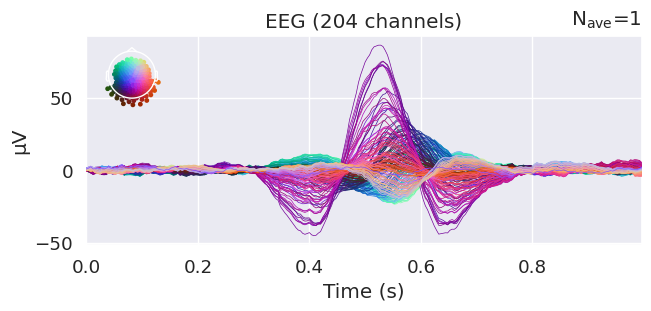

In [6]:
print(f"EEG maximum SNR: {max_snr[id]}")
print(f"EEG average SNR: {mean_snr[id]}")

_ = eegs[id].plot()

**<font color=green>Apply Source Reconstruction</font>**

In [17]:
# storage 
recons = {"cset":[], "sloreta":[]}

for eeg in eegs:
    recons["sloreta"].append(mm.sloreta(eeg, data["fwd"],  lam=0.01, win_size=None))
    recons["cset"].append(mm.cset(eeg, data["fwd"], data["cst"], lam=0.001, dw=0.8, win_size=None))

EEG channel type selected for re-referencing


/home/nino/Code/mindmap/mindmap/inverse.py:348: RuntimeWarning: An average reference projection was already added. The data has been left untouched.
  eeg.set_eeg_reference(projection=True)


EEG channel type selected for re-referencing


/home/nino/Code/mindmap/mindmap/inverse.py:348: RuntimeWarning: An average reference projection was already added. The data has been left untouched.
  eeg.set_eeg_reference(projection=True)


EEG channel type selected for re-referencing


/home/nino/Code/mindmap/mindmap/inverse.py:348: RuntimeWarning: An average reference projection was already added. The data has been left untouched.
  eeg.set_eeg_reference(projection=True)


... (142 outputs left out)

EEG channel type selected for re-referencing


/home/nino/Code/mindmap/mindmap/inverse.py:348: RuntimeWarning: An average reference projection was already added. The data has been left untouched.
  eeg.set_eeg_reference(projection=True)


EEG channel type selected for re-referencing


/home/nino/Code/mindmap/mindmap/inverse.py:348: RuntimeWarning: An average reference projection was already added. The data has been left untouched.
  eeg.set_eeg_reference(projection=True)


**<font color=violet>Select reconstruction to visualize</font>**

In [11]:
id = 1
t  = 0

#### Visualize CSET reconstruction

In [18]:
recon   = recons["cset"][id]
signal  = np.abs(recon.data[:,t])
p = mm.viz.plot_brain_signal(data["fwd"]["src"], signal, cmap="reds", show_max=True).show()

Widget(value='<iframe src="http://localhost:44335/index.html?ui=P_0x7df102bb8170_3&reconnect=auto" class="pyvi…

#### Visualize sLORETA reconstruction

In [11]:
recon = recons["sloreta"][id]
viz   = np.abs(recon.data[:,t])
mm.viz.plot_brain_signal(data["fwd"]["src"], viz, cmap="reds", show_max=True).show()

Widget(value='<iframe src="http://localhost:46667/index.html?ui=P_0x732b7ef46e70_3&reconnect=auto" class="pyvi…

**<font color=green>Measure localisation error at 50% rising phase</font>**

In [19]:
errors = {"cset 50%":[], "cset peak":[], "sloreta 50%":[], "sloreta peak":[]}

for i, eeg in enumerate(eegs):
    # source area
    r    = source_regions[i]
    area = data["parc"].create_mask(r)

    for key, t in zip(["cset 50%", "cset peak", "sloreta 50%", "sloreta peak"], [0,1,0,1]):
        recon = np.abs(recons[key.split()[0]][i].data[:,t])
        idx   = np.argmax(recon)
        loc   = pos[idx]

        errors[key].append(mm.utils.compute_distance(loc, area, m=1)[0])

errors = pd.DataFrame(errors)

#### Localisation error

In [13]:
errors

,cset 50%,cset peak,sloreta 50%,sloreta peak
0,0.576303,32.589238,3.403704,18.774846
1,2.186815,2.186815,2.186815,0.591740
2,0.524720,6.083807,2.315279,13.020663
3,13.085528,30.949087,11.179714,13.141063
4,0.543977,23.800283,0.555272,8.645718
...,...,...,...,...
71,0.640812,0.640812,0.742065,9.748677
72,0.475119,0.475119,5.555235,10.019323
73,5.501292,3.872477,4.688405,8.335775
74,5.633285,10.209776,8.964052,14.531313


Averages: 11.450889525957223, 17.221393637717167, 3.8979134751086124, 9.071648677278533


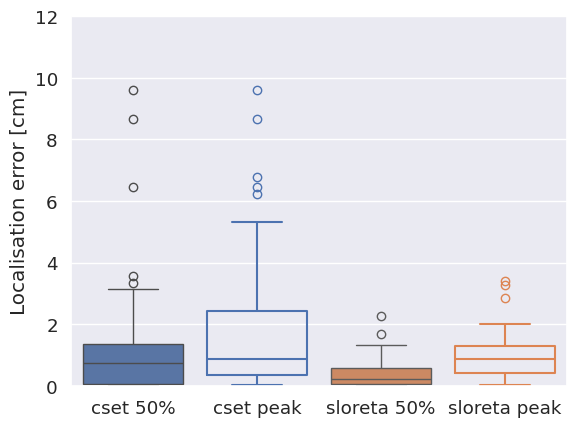

In [39]:
colors = sns.color_palette()
_ = sns.boxplot(data=errors[["cset 50%"]]/10, palette=[colors[0]], fill=True)
_ = sns.boxplot(data=errors[["cset peak"]]/10, palette=[colors[0]], fill=False)
_ = sns.boxplot(data=errors[["sloreta 50%"]]/10, palette=[colors[1]], fill=True)
_ = sns.boxplot(data=errors[["sloreta peak"]]/10, palette=[colors[1]], fill=False)

plt.ylabel("Localisation error [cm]")
plt.ylim(0, 12)
plt.title("")

print(f"Averages: {np.mean(errors["cset 50%"])}, {np.mean(errors["cset peak"])}, {np.mean(errors["sloreta 50%"])}, {np.mean(errors["sloreta peak"])}")

In [40]:
resultsCSETsLORETA = sp.stats.wilcoxon(errors["cset 50%"].values, errors["sloreta 50%"].values)
resultsCSET        = sp.stats.wilcoxon(errors["cset 50%"].values, errors["cset peak"].values)
resultsLORETA      = sp.stats.wilcoxon(errors["sloreta 50%"].values, errors["sloreta peak"].values)

print(resultsCSETsLORETA[1]*3)
print(resultsCSET[1]*3)
print(resultsLORETA[1]*3)

4.075946042368825e-06
0.003227713173841182
1.268878094161704e-07


**<font color=green>Measure spatial distribution match at peak EEG</font>**

In [30]:
correlations = {"cset":[], "sloreta":[]}

for i, eeg in enumerate(eegs):
    # ground truth
    _, pt  = mm.utils.eeg_rising_phase(eeg, 1)
    gt     = np.abs(gts[i].data[:,pt])
    gt_std = (gt - gt.mean())/np.std(gt)

    for key in ["cset", "sloreta"]:
        recon     = np.abs(recons[key.split()[0]][i].data[:,t])
        recon_std = (recon - recon.mean())/np.std(recon)
        corr      = np.sum(gt_std*recon_std)/(gt_std.shape[0]-1)
        
        correlations[key].append(corr)
    
correlations = pd.DataFrame(correlations)

Averages: 0.4054616946828493 and 0.3482407237225102


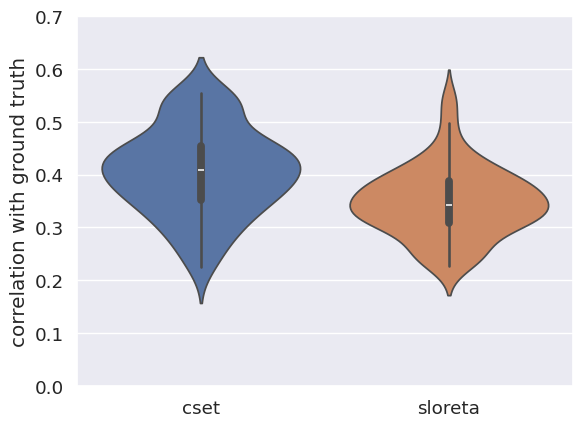

In [31]:
ax2 = sns.violinplot(data=correlations)

plt.ylim(0, 0.7)
plt.ylabel("correlation with ground truth")

print(f"Averages: {np.mean(correlations["cset"])} and {np.mean(correlations["sloreta"])}")

## Compare source localisation

#### Estimate source localisation

In [6]:
# ground truth source region
pos    = mm.utils.get_src_position(data["src"])
pos    = pos*1000 + data["cras"]
labels = data["parc"].label_points(pos)

idx    = np.argmax(np.abs(data["gt"].data))
idx    = np.unravel_index(idx, data["gt"].data.shape)[0]
region = labels[idx]

# time point for source localisation (50% rising phase)
time_point = ht - int(t_start*sfreq)        # time point in array position

# sLORETA source location
#idx         = np.argmax(np.abs(data["sloreta"].data[:,time_point]))
#sloreta_pos = pos[idx]

# CSET source location
idx      = np.argmax(np.abs(data["cset"].data[:,time_point]))
cset_pos = pos[idx]

#### Compute accuracy of estimation

In [13]:
area = data["parc"].create_mask(region)
dist = mm.utils.compute_distance(cset_pos, area, m=1)

## Compare network information

Figure out what metric you could measure to evaluate who is most informative about the underlying network

Idea: Measure sum of activity per region. These gives you a vector of size number of regions. Compare these vectors between ground truth, cset and sloreta

In [ ]:
def region_based_activity(stc, src, parc, cras):
    """
    Compute the dipole activity region wise.

    Parameters:
    ----------
    stc: mne.SourceEstimate
        Source time courses.

    src: mne.SourceSpaces
        Source spaces.

    parc: mm.Parcellation
        Parcellation.

    cras: np.ndarray (4,)
        Shift to go from freesurfer space to subject space.

    Returns:
    -------
    activity: np.ndarray (R,T)
        Region based activity.
    """
    pos    = mm.utils.get_src_position(src)
    pos    = pos*1000 + cras 
    labels = parc.label_points(pos, id=True)

    data     = stc.data
    regions  = parc.get_clut()["#No."].values
    activity = np.zeros((len(regions), data.shape[1]))
    
    for i, r in enumerate(regions):
        activity[i,:] = np.sum(data[labels==r], axis=0)

    return activity

gt_rb   = region_based_activity(data["gt"], data["src"], data["parc"], data["cras"])
cset_rb = region_based_activity(data["cset"], data["src"], data["parc"], data["cras"])

In [29]:
import numpy as np 
import scipy as sp 

def mutual_information(x, y, bins=10):
    # create joint histogram 
    joint_hist, xedges, yedges = np.histogram2d(x, y, bins=bins)

    # Normalize the joint histrogram to form a probability distribution
    joint_prob = joint_hist / joint_hist.sum()

    # Marginal histograms (probability distributions for each variable) 
    x_prob = joint_prob.sum(axis=1)
    y_prob = joint_prob.sum(axis=0) 

    # calculate the entropies 
    H_x = sp.stats.entropy(x_prob)
    H_y = sp.stats.entropy(y_prob)
    H_xy = sp.stats.entropy(joint_prob.flatten())

    # Mutual Information is the difference between the joint entropy and the marginal entropies
    return H_x + H_y - H_xy 


x = np.random.randint(0,10,100)
y = np.random.randint(0,10,100)

mi = mutual_information(x,y)
print(f"Mutual information: {mi}")

Mutual information: 0.4568663322075759


In [ ]:
import numpy as np